# 04 — Baselines

Dois pontos de referência:

1. **Dummy estratificado:** sorteia classes com as frequências do treino. É o piso: qualquer modelo útil precisa superá-lo.
2. **Regressão Logística multinomial:** modelo linear, interpretável, padrão na literatura de segurança viária.

Por padrão o notebook **carrega** os resultados gerados por `python -m src.train`. Com `RETREINAR = True` ele treina a Regressão Logística de novo (~1 min).

In [1]:
# Configuração: roda a partir da raiz do repositório
import os, sys, warnings
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
from src import config

In [2]:
RETREINAR = False
from src import data_processing as dp, evaluate as ev, train
base = dp.carregar_base()
params = train.carregar_params()
params["lr"]

{'pesos': 'nenhum', 'C': 10.0}

In [3]:
busca_lr = pd.read_csv(config.TABLES_DIR / "busca_lr.csv")
busca_lr[["C", "pesos", "f1_macro_ajustado", "f1_macro_argmax", "pr_auc_fatais", "roc_auc_macro", "segundos"]].round(3)

,C,pesos,f1_macro_ajustado,f1_macro_argmax,pr_auc_fatais,roc_auc_macro,segundos
0,10.00,nenhum,0.543,0.453,0.320,0.766,17.3
1,1.00,nenhum,0.543,0.453,0.320,0.766,17.1
2,0.10,nenhum,0.543,0.452,0.320,0.766,15.9
3,0.01,nenhum,0.542,0.446,0.320,0.766,13.7
4,10.00,raiz,0.542,0.534,0.319,0.765,19.2
5,0.01,raiz,0.542,0.533,0.319,0.765,14.0
6,10.00,balanceado,0.541,0.469,0.316,0.759,20.5
7,0.01,balanceado,0.540,0.469,0.317,0.759,14.3


A busca mostra o efeito dos pesos de classe: sem pesos, o `argmax` quase nunca prevê as classes raras (F1-macro baixo). Com o ajuste de limiar na validação, as três estratégias ficam próximas, porque o limiar compensa o desbalanceamento.

In [4]:
if RETREINAR:
    r = train.treinar_final(base, "lr", "A", params["lr"], salvar_modelo=False)
    y, pred, proba = r["y"], r["pred"], r["proba"]
else:
    p = pd.read_parquet(train.PRED_TESTE)
    y, pred = p["y"].to_numpy(), p["lr_A__pred"].to_numpy()
    proba = p[[f"lr_A__p{j}" for j in range(3)]].to_numpy()
pd.Series(ev.metricas(y, pred, proba)).round(3).to_frame("Regressão Logística — cenário A, teste 2025")

,"Regressão Logística — cenário A, teste 2025"
f1_macro,0.543
f1_ponderado,0.744
acuracia,0.747
roc_auc_macro_ovr,0.768
brier_medio,0.103
precision_sem,0.428
recall_sem,0.382
f1_sem,0.404
pr_auc_sem,0.466
precision_feridas,0.837


In [5]:
res = pd.read_csv(config.TABLES_DIR / "resultados_teste_2025.csv")
res[(res.modelo.isin(["dummy", "lr"]))][["modelo", "cenario", "f1_macro", "recall_fatais", "precision_fatais", "pr_auc_fatais", "roc_auc_macro_ovr", "acuracia"]].round(3)

,modelo,cenario,f1_macro,recall_fatais,precision_fatais,pr_auc_fatais,roc_auc_macro_ovr,acuracia
0,dummy,A,0.334,0.072,0.073,0.072,0.500,0.618
1,dummy,B,0.334,0.072,0.073,0.072,0.500,0.618
2,lr,A,0.543,0.382,0.375,0.316,0.768,0.747
3,lr,B,0.436,0.256,0.223,0.179,0.664,0.674


## Matriz de confusão e coeficientes

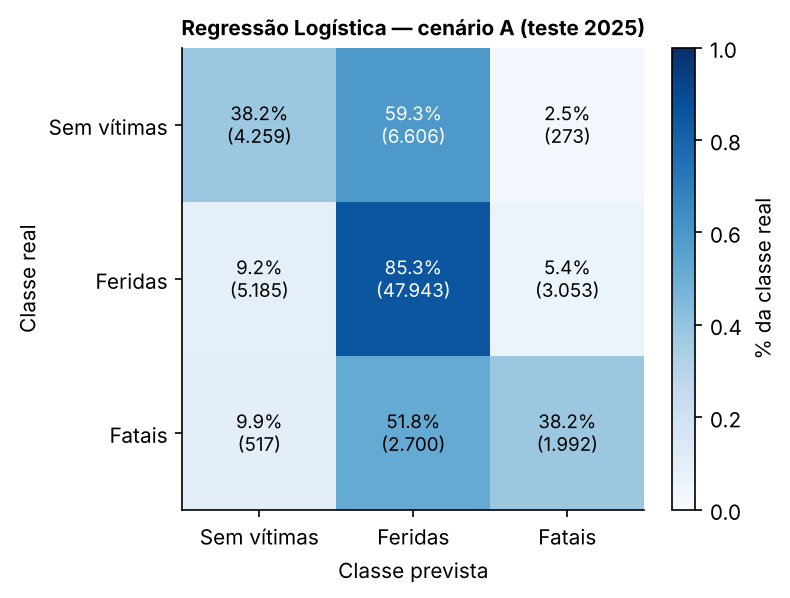

In [6]:
display(Image(str(config.FIGURES_DIR / "res_02b_matriz_confusao_lr_A.png")))

In [7]:
coef = pd.read_csv(config.TABLES_DIR / "coeficientes_lr_A.csv")
coef.head(15).round(3)

,variavel,coef_fatais,razao_chances
0,tipo_acidente_Atropelamento de Pedestre,2.245,9.436
1,tipo_acidente_Incêndio,-2.003,0.135
2,tipo_acidente_Colisão frontal,1.296,3.654
3,tipo_acidente_Engavetamento,-1.049,0.350
4,tipo_acidente_Derramamento de carga,-0.779,0.459
5,br_465,-0.645,0.524
6,br_405,0.569,1.767
7,tipo_acidente_Queda de ocupante de veículo,0.558,1.747
8,sentido_via_ausente,-0.540,0.583
9,br_354,-0.527,0.591


Os coeficientes são para a classe Fatais em contraste com a média das classes, em variáveis padronizadas (One-Hot ou escala z). Valores positivos aumentam a chance prevista de acidente fatal. Assim como na EDA, eles descrevem associações estatísticas, não causas.